## Part I: Data Pre-processing

In [13]:
import pandas as pd

In [14]:
# Download the Google Analogy dataset
!wget http://download.tensorflow.org/data/questions-words.txt

--2026-10-14 23:02:49--  http://download.tensorflow.org/data/questions-words.txt
Resolving download.tensorflow.org (download.tensorflow.org)... 192.178.142.207, 142.251.108.207, 142.251.121.207, ...
Connecting to download.tensorflow.org (download.tensorflow.org)|192.178.142.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 603955 (590K) [text/plain]
Saving to: ‘questions-words.txt.1’

questions-words.txt 100%[===================>] 589.80K  --.-KB/s    in 0.002s  

2026-10-14 23:02:49 (275 MB/s) - ‘questions-words.txt.1’ saved [603955/603955]



In [15]:
# Preprocess the dataset
file_name = "questions-words"
with open(f"{file_name}.txt", "r") as f:
    data = f.read().splitlines()

In [16]:
# check data from the first 10 entries
for entry in data[:10]:
    print(entry)

: capital-common-countries
Athens Greece Baghdad Iraq
Athens Greece Bangkok Thailand
Athens Greece Beijing China
Athens Greece Berlin Germany
Athens Greece Bern Switzerland
Athens Greece Cairo Egypt
Athens Greece Canberra Australia
Athens Greece Hanoi Vietnam
Athens Greece Havana Cuba


In [17]:
# TODO1: Write your code here for processing data to pd.DataFrame
# Please note that the first five mentions of ": " indicate `semantic`,
# and the remaining nine belong to the `syntatic` category.
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
questions = []
categories = []
sub_categories = []

num_sections = 0
for line in data:
    if line.startswith(": "):
        # A section header, e.g. ": capital-common-countries"
        num_sections += 1
        current_sub_category = line
        # Same labels as the official questions-words.csv
        current_category = "Semantic" if num_sections <= 5 else "Syntactic"
    else:
        questions.append(line)
        categories.append(current_category)
        sub_categories.append(current_sub_category)

In [18]:
# Create the dataframe
df = pd.DataFrame(
    {
        "Question": questions,
        "Category": categories,
        "SubCategory": sub_categories,
    }
)

In [19]:
df.head()

,Question,Category,SubCategory
0,Athens Greece Baghdad Iraq,Semantic,: capital-common-countries
1,Athens Greece Bangkok Thailand,Semantic,: capital-common-countries
2,Athens Greece Beijing China,Semantic,: capital-common-countries
3,Athens Greece Berlin Germany,Semantic,: capital-common-countries
4,Athens Greece Bern Switzerland,Semantic,: capital-common-countries


In [20]:
df.to_csv(f"{file_name}.csv", index=False)

## Part II: Use pre-trained word embeddings
- After finish Part I, you can run Part II code blocks only.

In [21]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Colab does not ship gensim by default
%pip install gensim

In [22]:
import pandas as pd
import numpy as np
import gensim.downloader
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

In [23]:
data = pd.read_csv("questions-words.csv")

In [24]:
MODEL_NAME = "glove-wiki-gigaword-100"
# You can try other models.
# https://radimrehurek.com/gensim/models/word2vec.html#pretrained-models

# Load the pre-trained model (using GloVe vectors here)
model = gensim.downloader.load(MODEL_NAME)
print("The Gensim model loaded successfully!")

[==================================================] 100.0% 128.1/128.1MB downloaded
The Gensim model loaded successfully!


In [25]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO2: Write your code here to use pre-trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      # Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
      # GloVe vocabulary is lowercase, so lowercase all four words
      word_a, word_b, word_c, word_d = analogy.lower().split()
      golds.append(word_d)
      try:
          # most_similar excludes the input words from the candidates
          pred = model.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
      except KeyError:
          # Some word is out of vocabulary: count it as a wrong prediction
          pred = None
      preds.append(pred)

100%|██████████| 19544/19544 [06:41<00:00, 48.62it/s]


In [26]:
# Perform evaluations. You do not need to modify this block!!

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: Semantic, Accuracy: 65.3399481339497%
Category: Syntactic, Accuracy: 61.255269320843084%
Sub-Category: capital-common-countries, Accuracy: 93.87351778656127%
Sub-Category: capital-world, Accuracy: 88.94783377541998%
Sub-Category: currency, Accuracy: 14.203233256351039%
Sub-Category: city-in-state, Accuracy: 30.806647750304013%
Sub-Category: family, Accuracy: 81.62055335968378%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 24.39516129032258%
Sub-Category: gram2-opposite, Accuracy: 20.073891625615765%
Sub-Category: gram3-comparative, Accuracy: 79.12912912912913%
Sub-Category: gram4-superlative, Accuracy: 54.278074866310156%
Sub-Category: gram5-present-participle, Accuracy: 69.50757575757575%
Sub-Category: gram6-nationality-adjective, Accuracy: 87.86741713570981%
Sub-Category: gram7-past-tense, Accuracy: 55.44871794871795%
Sub-Category: gram8-plural, Accuracy: 71.996996996997%
Sub-Category: gram9-plural-verbs, Accuracy: 58.39080459770115%


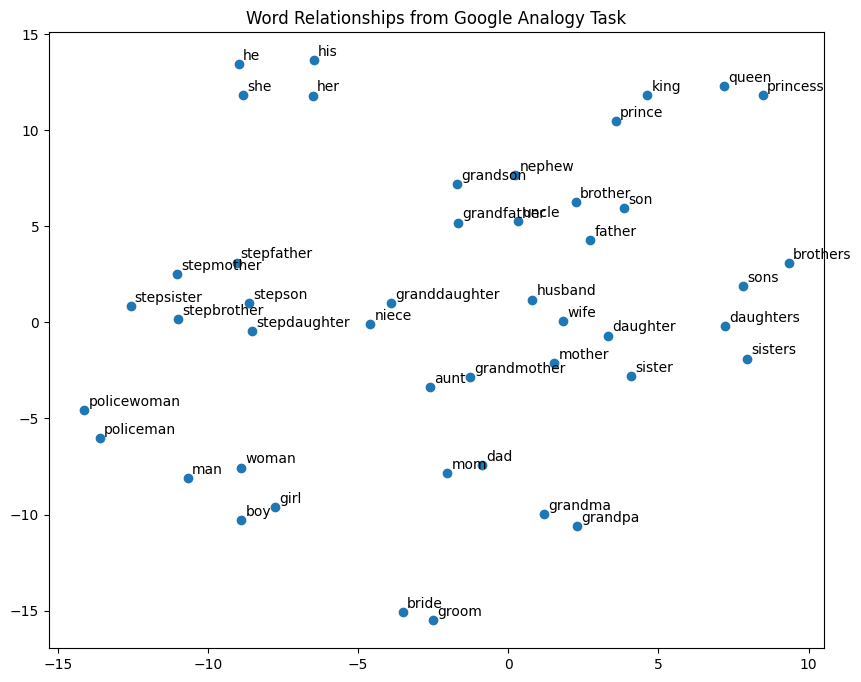

<Figure size 640x480 with 0 Axes>

In [27]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO3: Plot t-SNE for the words in the SUB_CATEGORY `: family`
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
family_questions = data.loc[data["SubCategory"] == SUB_CATEGORY, "Question"]
# Unique words, keeping first-seen order
words = list(dict.fromkeys(w for q in family_questions for w in q.lower().split()))
words = [w for w in words if w in model.key_to_index]
vectors = np.array([model[w] for w in words])

# perplexity must be smaller than the number of points
tsne = TSNE(n_components=2, perplexity=min(10, len(words) - 1), random_state=42)
coords = tsne.fit_transform(vectors)

plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1])
for word, (x, y) in zip(words, coords):
    plt.annotate(word, (x, y), xytext=(3, 3), textcoords="offset points")

plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

### Part III: Train your own word embeddings

### Get the latest English Wikipedia articles and do sampling.
- Usually, we start from Wikipedia dump (https://dumps.wikimedia.org/enwiki/latest/enwiki-latest-pages-articles.xml.bz2). However, the downloading step will take very long. Also, the cleaning step for the Wikipedia corpus ([`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus)) will take much time. Therefore, we provide cleaned files for you.

In [28]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles).
# NOTE: these original links failed with Google Drive's download quota error
# ("Too many users have viewed or downloaded this file recently"), so they are commented out.
# The Wikipedia files are loaded from my own copy of the course archive in the next cell instead.
# !gdown --id 1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd -O wiki_texts_part_0.txt.gz
# !gdown --id 1ABblLRd9HXdXvaNv8H9fFq984bhnowoG -O wiki_texts_part_1.txt.gz
# !gdown --id 1z2VFNhpPvCejTP5zyejzKj5YjI_Bn42M -O wiki_texts_part_2.txt.gz
# !gdown --id 1VKjded9BxADRhIoCzXy_W8uzVOTWIf0g -O wiki_texts_part_3.txt.gz
# !gdown --id 16mBeG26m9LzHXdPe8UrijUIc6sHxhknz -O wiki_texts_part_4.txt.gz

In [29]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles), except the last file.
# NOTE: these original links failed with Google Drive's download quota error
# ("Too many users have viewed or downloaded this file recently"), so they are commented out.
# The Wikipedia files are loaded from my own copy of the course archive in the next cell instead.
# !gdown --id 17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI -O wiki_texts_part_5.txt.gz
# !gdown --id 19IvB2vOJRGlrYulnTXlZECR8zT5v550P -O wiki_texts_part_6.txt.gz
# !gdown --id 1sjwO8A2SDOKruv6-8NEq7pEIuQ50ygVV -O wiki_texts_part_7.txt.gz
# !gdown --id 1s7xKWJmyk98Jbq6Fi1scrHy7fr_ellUX -O wiki_texts_part_8.txt.gz
# !gdown --id 17eQXcrvY1cfpKelLbP2BhQKrljnFNykr -O wiki_texts_part_9.txt.gz
# !gdown --id 1J5TAN6bNBiSgTIYiPwzmABvGhAF58h62 -O wiki_texts_part_10.txt.gz

In [31]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Workaround for the Google Drive download quota.
# Problem: every public link to the Wikipedia files failed. The per-part gdown links above (and the single
#   archive https://drive.google.com/file/d/1t4cqlZEgiRJCJJOzHeja3AjU1jTWiDRa linked in the course README)
#   returned "Too many users have viewed or downloaded this file recently", the alternative per-part links in
#   the README no longer exist, and a copy in my own Drive cannot be downloaded publicly either
#   ("Only the owner and editors can download this file").
# Solution: put the course archive wiki_texts.zip into my Google Drive and read it through the mounted Drive,
#   which uses my own Google account instead of a public download link. The archive contains the same
#   wiki_texts_part_0.txt.gz ... wiki_texts_part_10.txt.gz, so the following cells stay unchanged.
import os
from google.colab import drive

drive.mount("/content/drive")

WIKI_ZIP_PATH = "/content/drive/MyDrive/TAICA_NTHU_NLP/wiki_texts.zip"
if not os.path.exists(WIKI_ZIP_PATH):
    !ls -la /content/drive/MyDrive
    raise FileNotFoundError(f"{WIKI_ZIP_PATH} not found; update WIKI_ZIP_PATH to where wiki_texts.zip is in your Drive")

# Extract into /content (skip macOS metadata)
!unzip -o "{WIKI_ZIP_PATH}" -d /content -x "__MACOSX/*"

Mounted at /content/drive
Archive:  /content/drive/MyDrive/TAICA_NTHU_NLP/wiki_texts.zip
  inflating: /content/wiki_texts_part_10.txt.gz  
  inflating: /content/wiki_texts_part_9.txt.gz  
  inflating: /content/wiki_texts_part_8.txt.gz  
  inflating: /content/wiki_texts_part_7.txt.gz  
  inflating: /content/wiki_texts_part_6.txt.gz  
  inflating: /content/wiki_texts_part_5.txt.gz  
  inflating: /content/wiki_texts_part_4.txt.gz  
  inflating: /content/wiki_texts_part_3.txt.gz  
  inflating: /content/wiki_texts_part_2.txt.gz  
  inflating: /content/wiki_texts_part_1.txt.gz  
  inflating: /content/wiki_texts_part_0.txt.gz  


In [32]:
# Extract the downloaded wiki_texts_parts files.
# -f overwrites files left over from a failed earlier run
!gunzip -kf wiki_texts_part_*.gz

In [33]:
# Combine the extracted wiki_texts_parts files.
!cat wiki_texts_part_*.txt > wiki_texts_combined.txt

In [34]:
# Check the first ten lines of the combined file
!head -n 10 wiki_texts_combined.txt

anarchism is political philosophy and movement that is against all forms of authority and seeks to abolish the institutions it claims maintain unnecessary coercion and hierarchy typically including the state and capitalism anarchism advocates for the replacement of the state with stateless societies and voluntary free associations as historically left wing movement this reading of anarchism is placed on the farthest left of the political spectrum usually described as the libertarian wing of the socialist movement libertarian socialism although traces of anarchist ideas are found all throughout history modern anarchism emerged from the enlightenment during the latter half of the th and the first decades of the th century the anarchist movement flourished in most parts of the world and had significant role in workers struggles for emancipation various anarchist schools of thought formed during this period anarchists have taken part in several revolutions most notably in the paris commune

In [35]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Stop early if some Wikipedia parts failed to download (e.g. Google Drive quota errors),
# instead of silently training on an almost empty corpus
import os

missing_parts = [f"wiki_texts_part_{i}.txt" for i in range(11) if not os.path.exists(f"wiki_texts_part_{i}.txt")]
with open("wiki_texts_combined.txt", "rb") as f:
    num_articles = sum(1 for _ in f)
print(f"Missing parts: {missing_parts}")
print(f"Articles in wiki_texts_combined.txt: {num_articles}")
# Parts 0-9 contain 562365 articles each
assert not missing_parts and num_articles > 10 * 562365, (
    "Some Wikipedia parts are missing or incomplete. Re-run the download cells "
    "(or use the Google Drive link in the course README) before sampling."
)

Missing parts: []
Articles in wiki_texts_combined.txt: 5623655


Please note that we used the default parameters of [`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus) for cleaning the Wiki raw file. Thus, words with one character were discarded.

In [36]:
# Now you need to do sampling because the corpus is too big.
# You can further perform analysis with a greater sampling ratio.

import random

wiki_txt_path = "wiki_texts_combined.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
SAMPLE_RATIO = 0.2
output_path = f"wiki_texts_sampled_{int(SAMPLE_RATIO * 100)}.txt"
random.seed(42)

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # TODO4: Sample `20%` Wikipedia articles
    # Write your code here
        # Stream line by line so the whole corpus never sits in memory
        for line in f:
            if random.random() < SAMPLE_RATIO:
                output_file.write(line)

In [37]:
# TODO5: Train your own word embeddings with the sampled articles
# https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec
# Hint: You should perform some pre-processing before training.
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
import os
import logging
from gensim.models import Word2Vec

logging.basicConfig(format="%(asctime)s : %(levelname)s : %(message)s", level=logging.INFO)


def preprocess(line):
    # Lowercase, then keep only purely alphabetic (a-z) tokens
    return [tok for tok in line.lower().split() if tok.isascii() and tok.isalpha()]


# Pre-process once and write one cleaned article per line
cleaned_path = output_path.replace(".txt", "_cleaned.txt")
with open(output_path, "r", encoding="utf-8") as fin:
    with open(cleaned_path, "w", encoding="utf-8") as fout:
        for line in tqdm(fin):
            tokens = preprocess(line)
            if tokens:
                fout.write(" ".join(tokens) + "\n")

# corpus_file mode streams from disk, scales across workers,
# and splits articles longer than 10000 tokens instead of truncating them
w2v_model = Word2Vec(
    corpus_file=cleaned_path,
    vector_size=100,
    window=5,
    min_count=5,
    sg=0,
    negative=5,
    epochs=5,
    workers=os.cpu_count(),
    seed=42,
)
w2v_model.save(f"word2vec_wiki_{int(SAMPLE_RATIO * 100)}.model")
print(f"Vocabulary size: {len(w2v_model.wv)}")

1124733it [04:28, 4181.34it/s]


Vocabulary size: 983017


In [38]:
data = pd.read_csv("questions-words.csv")

In [39]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO6: Write your code here to use your trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      # Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
      # Our corpus was lowercased during pre-processing
      word_a, word_b, word_c, word_d = analogy.lower().split()
      golds.append(word_d)
      try:
          # most_similar excludes the input words from the candidates
          pred = w2v_model.wv.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
      except KeyError:
          # Some word is out of vocabulary (e.g. below min_count): count it as wrong
          pred = None
      preds.append(pred)

100%|██████████| 19544/19544 [20:05<00:00, 16.21it/s] 


In [40]:
# Generative AI usage: Claude (Anthropic) suggested inserting this unmodified copy of the evaluation block above to evaluate TODO6.
# Perform evaluations. You do not need to modify this block!!

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: Semantic, Accuracy: 65.15954448077574%
Category: Syntactic, Accuracy: 51.66276346604215%
Sub-Category: capital-common-countries, Accuracy: 81.22529644268775%
Sub-Category: capital-world, Accuracy: 77.38726790450929%
Sub-Category: currency, Accuracy: 16.05080831408776%
Sub-Category: city-in-state, Accuracy: 52.61451155249291%
Sub-Category: family, Accuracy: 84.98023715415019%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 21.370967741935484%
Sub-Category: gram2-opposite, Accuracy: 16.133004926108374%
Sub-Category: gram3-comparative, Accuracy: 71.32132132132132%
Sub-Category: gram4-superlative, Accuracy: 41.44385026737968%
Sub-Category: gram5-present-participle, Accuracy: 47.821969696969695%
Sub-Category: gram6-nationality-adjective, Accuracy: 81.48843026891808%
Sub-Category: gram7-past-tense, Accuracy: 48.78205128205128%
Sub-Category: gram8-plural, Accuracy: 56.15615615615616%
Sub-Category: gram9-plural-verbs, Accuracy: 50.57471264367817%


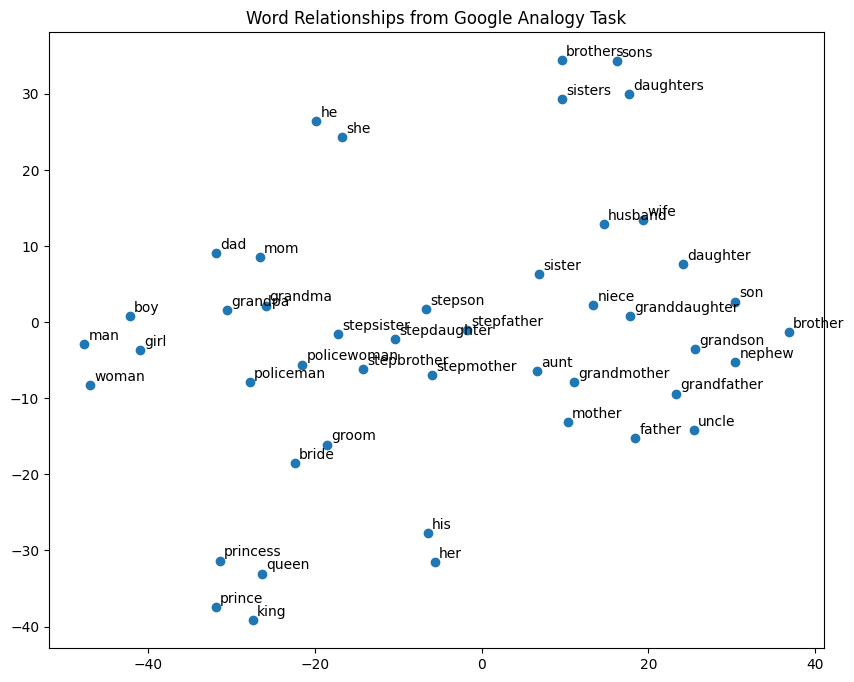

<Figure size 640x480 with 0 Axes>

In [41]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO7: Plot t-SNE for the words in the SUB_CATEGORY `: family`
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
family_questions = data.loc[data["SubCategory"] == SUB_CATEGORY, "Question"]
# Unique words, keeping first-seen order
words = list(dict.fromkeys(w for q in family_questions for w in q.lower().split()))
# Our model may miss rare words (below min_count)
words = [w for w in words if w in w2v_model.wv.key_to_index]
vectors = np.array([w2v_model.wv[w] for w in words])

# perplexity must be smaller than the number of points
tsne = TSNE(n_components=2, perplexity=min(10, len(words) - 1), random_state=42)
coords = tsne.fit_transform(vectors)

plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1])
for word, (x, y) in zip(words, coords):
    plt.annotate(word, (x, y), xytext=(3, 3), textcoords="offset points")

plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

Running environment:
- Part I–III (TODO1–7, including the 20% Wikipedia training): Google Colab (T4 runtime; Word2Vec uses the CPU only)
- Report experiments (code for Q2–Q5): local machine, macOS 26.3, Apple M5 (10 CPU cores), because the extra trainings were too slow on Colab's 2 vCPUs and the Colab runtime kept resetting

Python version:
- Colab: Python 3.13
- Local: Python 3.13.15 (gensim 4.4.0, the same gensim version as on Colab)

##### 1. Which embedding model do you use? What are the pre-processing steps? What are the hyperparameter settings? (5%)

Answer:

**Embedding models**
- Part II (pre-trained): GloVe `glove-wiki-gigaword-100` loaded with `gensim.downloader` (100-dimensional vectors, lowercase vocabulary, trained on Wikipedia + Gigaword).
- Part III (my own): gensim `Word2Vec` with the CBOW architecture, trained on a 20% random sample of the provided Wikipedia articles (`random.seed(42)`, each article kept with probability 0.2).

**Pre-processing**
- The provided Wikipedia files were already cleaned by `gensim.corpora.wikicorpus.WikiCorpus` (lowercased, punctuation removed, tokens shorter than 2 or longer than 15 characters dropped).
- On top of that, I lowercase every token and keep only purely alphabetic ASCII tokens, so numbers (e.g. `1990`), mixed tokens (e.g. `3d`) and non-English scripts are removed. Each article is written as one line of space-separated tokens.
- I deliberately do not remove stop words or lemmatize: lemmatization would merge the word forms that the syntactic analogies test (e.g. `big` / `biggest`), and stop-word removal deletes analogy words such as `he`, `she`, `his` and `her` (see Q5).
- The four words of every analogy question are lowercased to match the vocabularies.

**Hyperparameters (Word2Vec)**

| Parameter | Value |
|---|---|
| architecture | CBOW (`sg=0`) |
| `vector_size` | 100 (same dimension as GloVe-100 for a fair comparison) |
| `window` | 5 |
| `min_count` | 5 |
| training objective | negative sampling, `negative=5` |
| `epochs` | 5 |
| `sample`, `alpha`, `min_alpha` | gensim defaults (1e-3, 0.025, 0.0001) |
| `workers` | number of CPU cores (`os.cpu_count()`) |
| `seed` | 42 |
| input | `corpus_file` mode (streams from disk; articles longer than 10,000 tokens are split rather than truncated) |

CBOW was chosen over skip-gram because skip-gram is considerably slower on Colab's few CPU cores (gensim's Word2Vec does not use the GPU); Q5 compares the two.

**Analogy prediction**: 3CosAdd via `most_similar(positive=[b, c], negative=[a], topn=1)`, which excludes the three query words from the candidates. A question containing an out-of-vocabulary word is counted as wrong.

##### 2. What will the performance be like if you sample 5%, 10% and 20% of wiki text in TODO4? (10%, 3% for each)

Answer:

The three samples are nested (5% ⊂ 10% ⊂ 20%, one random number per article with `random.seed(42)`), and every model uses exactly the same pre-processing and hyperparameters as TODO5, so the corpus size is the only difference. These models were trained in the local run of Q2–Q5; the local 20% model (vocabulary 982,137) is a retrained counterpart of the Colab TODO5 model (vocabulary 983,017, TODO6: 65.16% semantic / 51.66% syntactic), and the two give very similar results.

| Accuracy (%) | 5% | 10% | 20% |
|---|---|---|---|
| Semantic | 59.45 | 62.06 | **65.05** |
| Syntactic | 47.81 | 49.88 | **52.83** |
| Overall | 53.10 | 55.41 | **58.38** |
| Vocabulary size | 418,105 | 645,723 | 982,137 |
| Questions with OOV words | 0.17% | 0.00% | 0.00% |

- **5%:** 53.10% overall. Even 5% of Wikipedia (about 0.28M articles) already learns most relations, and almost every analogy word is in the vocabulary (0.17% OOV questions).
- **10%:** 55.41% overall (+2.31). The largest gains are in knowledge-heavy semantic relations (`capital-world` 70.31 → 74.82, `currency` 8.43 → 12.01) and `gram4-superlative` (34.58 → 40.02).
- **20%:** 58.38% overall (+2.97), the best of the three. Both categories keep improving, e.g. `capital-world` 77.79, `family` 90.32, `gram8-plural` 58.26.

More data helps because rare words (many country capitals, currencies and superlatives) get more training contexts, so their vectors become more reliable. The gain did not saturate between 10% and 20%, so a larger sample would probably still help. A few sub-categories barely change (`capital-common-countries` ≈ 81–83%, `gram1-adjective-to-adverb` ≈ 20–21%): the former involves very frequent words that are learned well even from 5%, while the latter stays hard for 3CosAdd at every size.

##### 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

3.1. Present your results. (5%)

Answer:

Both models use the same pre-processing and hyperparameters (TODO5); see the table and bar chart in "Code For 3".

| Accuracy (%) | Wiki 20% | CC-News | CC-News − Wiki |
|---|---|---|---|
| **Semantic** | **65.05** | **38.08** | **−26.97** |
| capital-common-countries | 81.23 | 69.76 | −11.46 |
| capital-world | 77.79 | 43.79 | −34.00 |
| currency | 13.63 | 9.12 | −4.50 |
| city-in-state | 51.24 | 24.12 | −27.12 |
| family | 90.32 | 72.92 | −17.39 |
| **Syntactic** | **52.83** | **47.79** | **−5.04** |
| gram1-adjective-to-adverb | 20.97 | 15.02 | −5.95 |
| gram2-opposite | 18.10 | 14.66 | −3.45 |
| gram3-comparative | 73.87 | 70.35 | −3.53 |
| gram4-superlative | 43.23 | 47.42 | +4.19 |
| gram5-present-participle | 46.69 | 60.80 | +14.11 |
| gram6-nationality-adjective | 82.93 | 60.29 | −22.64 |
| gram7-past-tense | 49.04 | 50.83 | +1.79 |
| gram8-plural | 58.26 | 40.17 | −18.09 |
| gram9-plural-verbs | 52.41 | 49.54 | −2.87 |
| **Overall** | **58.38** | **43.38** | **−14.99** |
| Questions with OOV words | 0.00% | 0.70% | |

3.2. Introduce the corpus you selected and explain what are the differences between the Wikipedia corpus and your corpus. (including data size, topic difference, structural difference … ) (5%)

Answer:

**Corpus:** CC-News, data source: https://huggingface.co/datasets/vblagoje/cc_news. It contains 708,241 English news articles from news sites around the world, published between January 2017 and December 2019. It was extracted from the CC-NEWS crawl of Common Crawl with the news-please crawler. I tokenized it with the same tokenizer that `WikiCorpus` used for the provided Wikipedia files and then applied the TODO5 pre-processing, so both corpora went through identical cleaning.

| | Wiki 20% | CC-News |
|---|---|---|
| Documents | 1,124,733 articles | 708,241 articles |
| Tokens (after pre-processing) | 665,741,874 | 268,624,655 (≈ 40% of Wiki 20%) |
| Average tokens per document | ≈ 592 | ≈ 379 |
| Vocabulary (`min_count=5`) | 982,137 | 254,605 |
| Time span | encyclopedic, not tied to a period | news from 2017–2019 |

- **Data size:** CC-News has about 40% of the tokens of the Wiki 20% sample, which is between our 5% and 10% Wikipedia samples (≈ 166M and ≈ 333M tokens), and a vocabulary about one quarter as large.
- **Topic:** Wikipedia covers every topic systematically: every country, capital, US city, currency and historical person has its own article. CC-News is driven by current events (politics, business, sports, entertainment, technology), so it repeatedly covers a small set of popular entities and rarely mentions small countries or towns.
- **Structure and style:** Wikipedia articles are long, neutral and written in the third person, with definitions, lists and dense factual relations ("X is the capital of Y", "his son …"). News articles are shorter, narrative and event-centered, with quotations and reported speech ("said", "announced", "is expected to"), and tied to the time they were written.

3.3. Explain why the performance increases or decreases. (5%)

Answer:

Overall accuracy decreases from 58.38% to 43.38%, but almost all of the drop is semantic (−26.97) and much less is syntactic (−5.04).

- **Not mainly a data-size effect.** CC-News has fewer tokens than Wiki 20%, but even our 5% and 10% Wikipedia samples, which have a similar or smaller number of tokens, reach 53.10% and 55.41% overall. They are about 10 points better than CC-News. So most of the gap comes from what the corpus talks about and how it is written, not from its size.
- **Semantic relations need encyclopedic world knowledge.** `capital-world` (−34.00), `city-in-state` (−27.12) and `gram6-nationality-adjective` (−22.64) require many small countries, capitals and US cities to appear in informative contexts. Wikipedia has dedicated articles for all of them, whereas news only mentions frequently reported places. This also explains why `capital-common-countries` (big, frequently reported countries) drops much less (−11.46) than `capital-world`. `family` (−17.39) benefits from Wikipedia biographies, which systematically list relatives (son, daughter, wife, uncle …).
- **Some syntactic relations improve with news style.** News is narrative and full of ongoing and past actions, so `gram5-present-participle` (+14.11), `gram4-superlative` (+4.19, e.g. "the biggest", "the best") and `gram7-past-tense` (+1.79) are better than on Wikipedia, even though CC-News is smaller. Relations involving rarer or encyclopedic words, such as `gram8-plural` (−18.09) and nationality adjectives, decrease.
- **Vocabulary coverage.** A few analogy words are missing from the CC-News vocabulary (0.70% of the questions contain an OOV word), which counts as wrong, but this explains only a small part of the gap.

##### 4. Select a few words and use their embeddings to retrieve the five most similar words. What do you observe?  (10%)

Answer:

Top-5 most similar words (cosine similarity) for six words in the three models (see "Code For 4"):

| Word | GloVe (Wikipedia 2014 + Gigaword) | Wiki 20% (my Word2Vec) | CC-News (my Word2Vec) |
|---|---|---|---|
| king | prince, queen, son, brother, monarch | prince, queen, monarch, ethelred, eadred | augustus, caesar, queen, tiberius, shatner |
| apple | microsoft, ibm, intel, software, dell | iigs, blackberry, ibook, macintosh, iphone | iphone, samsung, microsoft, google, htc |
| bank | banks, banking, credit, investment, financial | banks, hsbc, bancorporation, banking, corporation | lender, sbi, banks, cibc, telekom |
| trump | nows, hilton, casino, ivanka, mih | obama, biden, reagan, nixon, putin | rumsfeld, obama, putin, maduro, duterte |
| taiwan | mainland, china, taiwanese, taipei, hong | china, japan, guangdong, taiwanese, hainan | china, japan, taiwanese, beijing, chinese |
| happy | 'm, feel, 're, i, 'll | lonely, crazy, lovely, sad, forever | thrilled, excited, glad, pleased, nice |

Observations:
- **The corpus decides the dominant sense of a word.** `apple` is a company in all three models and never the fruit. The flavor differs, though: classic computer companies in GloVe (ibm, dell), Apple's product history in Wikipedia (iigs, ibook, macintosh) and the smartphone market in news (iphone, samsung, htc). `bank` is always the financial institution; CC-News adds lender names (sbi, cibc).
- **The time of the corpus matters.** In GloVe, which was trained on Wikipedia 2014 and older newswire (Gigaword), `trump` is still a businessman (hilton, casino, ivanka). In both of my models, which use newer text, he is a politician (obama, biden, putin, maduro, duterte).
- **Encyclopedic vs. news contexts.** In Wikipedia, `king` is close to historical English kings (ethelred, eadred); in CC-News it is close to Roman emperors and even an actor (shatner), probably because these names appear in reviews of films and TV series.
- **Similar words are not always synonyms.** Word2Vec puts words that appear in the same contexts close together, so antonyms appear: `happy` is close to `sad` and `lonely` in Wikipedia. In GloVe, `happy` is close to clitics such as `'m` and `'re` because of conversational text ("I'm happy"). CC-News gives the most synonym-like neighbors (thrilled, excited, glad, pleased), which is typical of quotes in news.
- Geographic words are stable across corpora (`taiwan` → china, japan, taiwanese, taipei/beijing), because their contexts are similar in every kind of text.

##### 5. … Anything that can strengthen your report.  (5%)

Answer:

I ran two additional experiments (see "Code For 5").

**(1) 3CosAdd vs. 3CosMul.** 3CosMul (Levy & Goldberg, 2014, https://aclanthology.org/W14-1618/) replaces the additive objective of `most_similar` with a multiplicative one (`most_similar_cosmul`). It needs no retraining.

| Overall accuracy (%) | 3CosAdd | 3CosMul |
|---|---|---|
| GloVe | **63.11** | 59.32 |
| Wiki 20% | **58.38** | 53.04 |
| CC-News | **43.38** | 38.86 |

In my setting 3CosMul is 4–5 points worse overall for all three embeddings, and lower in every category and sub-category, so I kept 3CosAdd for all other results.

**(2) Word2Vec variants on the 5% Wikipedia sample.** I changed one setting at a time compared with the TODO5 configuration (CBOW, 100 dimensions).

| Accuracy (%) | baseline (CBOW, 100d) | skip-gram | vector_size=50 | vector_size=300 | no stop words |
|---|---|---|---|---|---|
| Semantic | 59.45 | 55.80 | 45.61 | **66.29** | 64.65 |
| Syntactic | 47.81 | 38.95 | 36.88 | **55.88** | 44.18 |
| Overall | 53.10 | 46.60 | 40.84 | **60.60** | 53.47 |
| Questions with OOV words | 0.17% | 0.17% | 0.17% | 0.17% | 4.52% |

- **Vector size has the largest effect.** 50 dimensions lose 12 points, while 300 dimensions gain 7.5 points. 300-dimensional vectors trained on only 5% of Wikipedia (60.60%) even beat the 100-dimensional model trained on 20% (58.38%), so the embedding size is a stronger lever than the corpus size in this range.
- **Skip-gram is worse here (−6.5 overall).** This holds with the same hyperparameters and only 5 epochs, and mainly affects syntactic relations (e.g. superlative 34.58 → 18.89). Skip-gram is slightly better on rare-entity relations (`capital-common-countries` +2.96, `capital-world` +0.98, `gram6-nationality-adjective` +4.32), but CBOW is better overall in this setting, which supports the choice made in TODO5. Skip-gram usually needs different settings (e.g. more epochs), which I did not tune.
- **Stop-word removal is a trade-off.** Semantic accuracy improves (+5.20), because removing frequent function words lets each context window cover more content words. Syntactic accuracy drops (−3.63; `gram9-plural-verbs` −20.92, `gram5-present-participle` −15.82), likely because function words such as pronouns carry the grammatical context. In addition, gensim's stop-word list removes 14 analogy words (he, she, his, her, computer, find, say, see, go, most, mostly, move, describe, serious). These words become out of vocabulary, so 4.52% of the questions cannot be answered and `family` drops by 16 points. This is why I did not remove stop words in TODO5.

##### 6. Generative AI Usage

Answer: **Contribution statement:** All key decisions, the execution of all experiments and the interpretation of results were made by me; generative AI was used as an assistant for code writing, option proposals and analysis. I have checked and understood all submitted code and text, and I take full responsibility for them. I studied the generated code to understand how each step works.


## Code For 2. What will the performance be like if you sample 5%, 10% and 20% of wiki text in TODO4?

In [1]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Setup for the report experiments (Q2-Q5). Q2-Q5 were run on a local machine (macOS, 10-core CPU,
# Python 3.13) instead of Colab: Colab's 2 vCPUs made the extra Word2Vec trainings take many hours and
# its runtime kept resetting. This cell makes Q2-Q5 independent of Part I-III, so after a kernel restart
# only this cell needs to be re-run.
import os
import random
import logging
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gensim.downloader
from gensim.models import Word2Vec
from tqdm import tqdm as _tqdm

# Fewer progress-bar refreshes keep the saved notebook outputs small
tqdm = partial(_tqdm, mininterval=30)
# Training progress goes to training.log instead of the notebook output
logging.basicConfig(filename="training.log", format="%(asctime)s : %(levelname)s : %(message)s",
                    level=logging.INFO, force=True)

wiki_txt_path = "wiki_texts_combined.txt"


def preprocess(line):
    # Same pre-processing as TODO5: lowercase, then keep only purely alphabetic (a-z) tokens
    return [tok for tok in line.lower().split() if tok.isascii() and tok.isalpha()]

In [2]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Helpers shared by the Q2, Q3 and Q5 experiments


def clean_corpus(raw_path):
    # Same pre-processing as TODO5: one cleaned document per line
    cleaned = raw_path.replace(".txt", "_cleaned.txt")
    with open(raw_path, "r", encoding="utf-8") as fin:
        with open(cleaned, "w", encoding="utf-8") as fout:
            for line in tqdm(fin, desc=f"Cleaning {raw_path}"):
                tokens = preprocess(line)
                if tokens:
                    fout.write(" ".join(tokens) + "\n")
    return cleaned


# Same hyperparameters as TODO5
W2V_PARAMS = dict(vector_size=100, window=5, min_count=5, sg=0, negative=5, epochs=5, seed=42)


def train_word2vec(cleaned_path, **overrides):
    # Defaults match TODO5 so only the corpus differs; Q5 overrides single hyperparameters
    params = {**W2V_PARAMS, **overrides}
    return Word2Vec(corpus_file=cleaned_path, workers=os.cpu_count(), **params)


def evaluate_analogy(kv, use_cosmul=False):
    # Accuracy (%) per Category and SubCategory, same metric as the evaluation cell.
    # Also reports how many questions contain an out-of-vocabulary word.
    # use_cosmul=True switches 3CosAdd (most_similar) to 3CosMul (most_similar_cosmul).
    data = pd.read_csv("questions-words.csv")
    most_similar = kv.most_similar_cosmul if use_cosmul else kv.most_similar
    golds, preds = [], []
    for analogy in tqdm(data["Question"], desc="Analogy"):
        word_a, word_b, word_c, word_d = analogy.lower().split()
        golds.append(word_d)
        try:
            pred = most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
        except KeyError:
            pred = None
        preds.append(pred)
    data["correct"] = np.array(golds) == np.array(preds)
    data["oov"] = [p is None for p in preds]
    scores = pd.concat([
        data.groupby("Category", sort=False)["correct"].mean(),
        data.groupby("SubCategory", sort=False)["correct"].mean(),
        pd.Series({"overall": data["correct"].mean(), "OOV questions": data["oov"].mean()}),
    ])
    return scores * 100

In [3]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Nested sampling in a single pass over the full corpus.
# One random number per article with the same seed as TODO4, so `x < 0.2`
# reproduces the TODO4 sample exactly and 5% ⊂ 10% ⊂ 20%:
# the three corpora differ only in size.
RATIOS = [0.05, 0.10, 0.20]
sample_paths = {r: f"wiki_texts_sampled_{round(r * 100)}.txt" for r in RATIOS}
# The 20% file already exists from TODO4
ratios_to_write = [r for r in RATIOS if not os.path.exists(sample_paths[r])]

random.seed(42)
outs = {r: open(sample_paths[r], "w", encoding="utf-8") for r in ratios_to_write}
with open(wiki_txt_path, "r", encoding="utf-8") as f:
    for line in tqdm(f, desc="Sampling"):
        x = random.random()
        for r, out in outs.items():
            if x < r:
                out.write(line)
for out in outs.values():
    out.close()

Sampling: 0it [00:00, ?it/s]

Sampling: 5623655it [00:12, 450962.49it/s]

In [4]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Train (or load) one model per ratio and compare analogy accuracy
q2_results = {}
for r in RATIOS:
    name = f"{round(r * 100)}%"
    model_path = f"word2vec_wiki_{round(r * 100)}.model"
    if os.path.exists(model_path):
        # e.g. the 20% model saved by TODO5
        m = Word2Vec.load(model_path)
    else:
        m = train_word2vec(clean_corpus(sample_paths[r]))
        m.save(model_path)
    print(f"{name} vocab size: {len(m.wv)}")
    q2_results[name] = evaluate_analogy(m.wv)

q2_table = pd.DataFrame(q2_results).round(2)
q2_table

5% vocab size: 418105


Analogy: 100%|██████████| 19544/19544 [01:27<00:00, 223.54it/s]
Cleaning wiki_texts_sampled_10.txt: 563148it [00:23, 23636.19it/s]
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
[... 380 more identical 'Exception ignored' lines removed from this output to reduce its size ...]


10% vocab size: 645723


Analogy: 100%|██████████| 19544/19544 [02:12<00:00, 147.79it/s]
Cleaning wiki_texts_sampled_20.txt: 1124733it [00:46, 24014.68it/s]


20% vocab size: 982137


Analogy: 100%|██████████| 19544/19544 [03:14<00:00, 100.45it/s]


,5%,10%,20%
Semantic,59.45,62.06,65.05
Syntactic,47.81,49.88,52.83
: capital-common-countries,82.81,81.82,81.23
: capital-world,70.31,74.82,77.79
: currency,8.43,12.01,13.63
: city-in-state,47.79,47.43,51.24
: family,83.20,85.18,90.32
: gram1-adjective-to-adverb,19.96,19.56,20.97
: gram2-opposite,14.16,15.76,18.10
: gram3-comparative,67.72,69.37,73.87


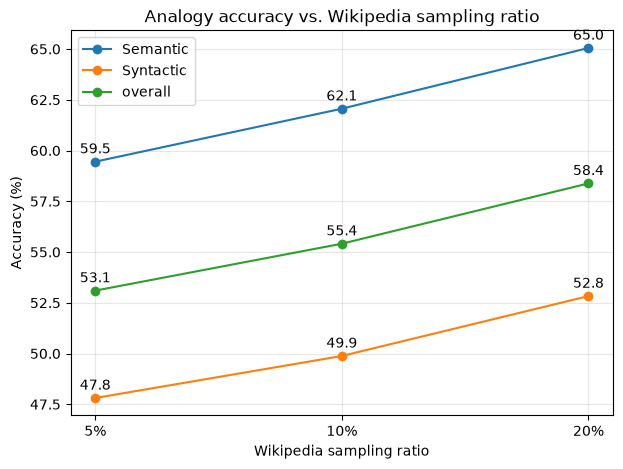

In [5]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Accuracy vs. sampling ratio
ratio_labels = list(q2_table.columns)
plt.figure(figsize=(7, 5))
for row in ["Semantic", "Syntactic", "overall"]:
    plt.plot(ratio_labels, q2_table.loc[row], marker="o", label=row)
    for x, y in zip(ratio_labels, q2_table.loc[row]):
        plt.annotate(f"{y:.1f}", (x, y), xytext=(0, 6), textcoords="offset points", ha="center")
plt.xlabel("Wikipedia sampling ratio")
plt.ylabel("Accuracy (%)")
plt.title("Analogy accuracy vs. Wikipedia sampling ratio")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("q2_accuracy_vs_ratio.png", bbox_inches="tight")
plt.show()

## Code For 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

In [6]:
# Write your code here
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Corpus: CC-News (https://huggingface.co/datasets/vblagoje/cc_news), 708k English news articles
%pip install datasets
from datasets import load_dataset
from gensim.corpora.wikicorpus import tokenize as wiki_tokenize

ccnews = load_dataset("vblagoje/cc_news", split="train")
print(ccnews)

# The provided wiki files were already tokenized by WikiCorpus, but CC-News is raw text
# (punctuation attached, e.g. "Paris,"). Tokenize it the same way first so both corpora
# go through identical cleaning; clean_corpus() then applies the TODO5 pre-processing.
ccnews_raw_path = "ccnews_texts.txt"
with open(ccnews_raw_path, "w", encoding="utf-8") as fout:
    for batch in tqdm(ccnews.iter(batch_size=1000), total=-(-len(ccnews) // 1000), desc="Tokenizing CC-News"):
        for text in batch["text"]:
            tokens = wiki_tokenize(text)
            if tokens:
                fout.write(" ".join(tokens) + "\n")

ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.


Note: you may need to restart the kernel to use updated packages.


README.md:   0%|          | 0.00/7.57k [00:00<?, ?B/s]

plain_text/train-00000-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  211MB            

plain_text/train-00000-of-00005.parquet: downloading bytes:           |  0.00B            

plain_text/train-00001-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  234MB            

... (12 outputs left out)

Tokenizing CC-News:  63%|██████▎   | 448/709 [01:00<00:35,  7.40it/s]

Tokenizing CC-News:  63%|██████▎   | 448/709 [01:10<00:35,  7.40it/s]

Tokenizing CC-News:  94%|█████████▍| 666/709 [01:30<00:05,  7.33it/s]

Tokenizing CC-News: 100%|██████████| 709/709 [01:36<00:00,  7.35it/s]

In [7]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Train on CC-News with the same pre-processing and hyperparameters, then compare with Wiki 20%
ccnews_cleaned_path = clean_corpus(ccnews_raw_path)
ccnews_model_path = "word2vec_ccnews.model"
if os.path.exists(ccnews_model_path):
    ccnews_model = Word2Vec.load(ccnews_model_path)
else:
    ccnews_model = train_word2vec(ccnews_cleaned_path)
    ccnews_model.save(ccnews_model_path)
wiki20_model = Word2Vec.load("word2vec_wiki_20.model")


def corpus_stats(cleaned_path, model):
    num_docs, num_tokens = 0, 0
    with open(cleaned_path, "r", encoding="utf-8") as f:
        for line in f:
            num_docs += 1
            num_tokens += line.count(" ") + 1
    return {"documents": num_docs, "tokens": num_tokens, "vocab size": len(model.wv)}


# Corpus size comparison (for 3.2)
q3_stats = pd.DataFrame({
    "Wiki 20%": corpus_stats("wiki_texts_sampled_20_cleaned.txt", wiki20_model),
    "CC-News": corpus_stats(ccnews_cleaned_path, ccnews_model),
})
print(q3_stats)

q3_table = pd.DataFrame({
    "Wiki 20%": evaluate_analogy(wiki20_model.wv),
    "CC-News": evaluate_analogy(ccnews_model.wv),
})
q3_table["CC-News − Wiki"] = q3_table["CC-News"] - q3_table["Wiki 20%"]
q3_table = q3_table.round(2)
q3_table

Cleaning ccnews_texts.txt: 708241it [00:17, 41495.93it/s]
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
[... 166 more identical 'Exception ignored' lines removed from this output to reduce its size ...]


             Wiki 20%    CC-News
documents     1124733     708241
tokens      665741874  268624655
vocab size     982137     254605


Analogy: 100%|██████████| 19544/19544 [00:53<00:00, 365.48it/s]


,Wiki 20%,CC-News,CC-News − Wiki
Semantic,65.05,38.08,-26.97
Syntactic,52.83,47.79,-5.04
: capital-common-countries,81.23,69.76,-11.46
: capital-world,77.79,43.79,-34.00
: currency,13.63,9.12,-4.50
: city-in-state,51.24,24.12,-27.12
: family,90.32,72.92,-17.39
: gram1-adjective-to-adverb,20.97,15.02,-5.95
: gram2-opposite,18.10,14.66,-3.45
: gram3-comparative,73.87,70.35,-3.53


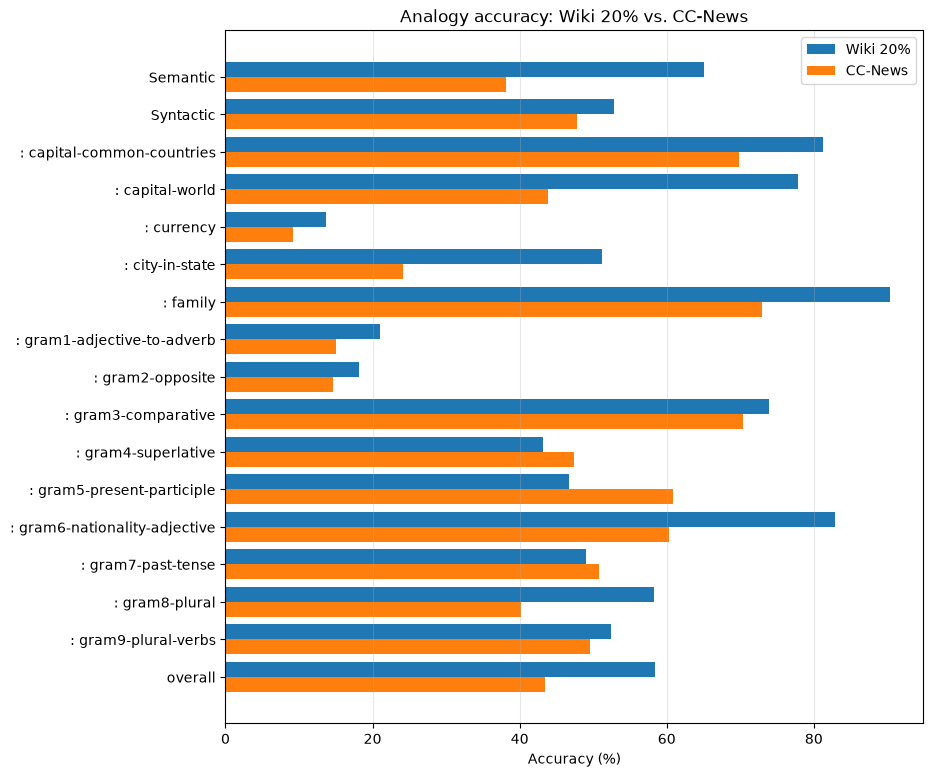

In [8]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Per-category / sub-category accuracy: Wiki 20% vs. CC-News
plot_rows = [row for row in q3_table.index if row != "OOV questions"]
y = np.arange(len(plot_rows))
bar_height = 0.4

plt.figure(figsize=(9, 9))
plt.barh(y - bar_height / 2, q3_table.loc[plot_rows, "Wiki 20%"], bar_height, label="Wiki 20%")
plt.barh(y + bar_height / 2, q3_table.loc[plot_rows, "CC-News"], bar_height, label="CC-News")
plt.yticks(y, plot_rows)
plt.gca().invert_yaxis()
plt.xlabel("Accuracy (%)")
plt.title("Analogy accuracy: Wiki 20% vs. CC-News")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.savefig("q3_corpus_comparison.png", bbox_inches="tight")
plt.show()

## Code For 4. Select a few words and use their embeddings to retrieve the five most similar words.

In [9]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
from IPython.display import display

# At least five words: a classic example, polysemous words (apple, bank),
# a news-heavy entity (trump), a place (taiwan) and an adjective (happy)
Q4_WORDS = ["king", "apple", "bank", "trump", "taiwan", "happy"]

# GloVe from Part II (reload it if Part II was not run in this session)
glove_kv = model if "model" in globals() else gensim.downloader.load("glove-wiki-gigaword-100")
q4_models = {
    "GloVe": glove_kv,
    "Wiki 20%": wiki20_model.wv,
    "CC-News": ccnews_model.wv,
}

q4_rows = []
for word in Q4_WORDS:
    for model_name, kv in q4_models.items():
        if word in kv.key_to_index:
            top5 = ", ".join(f"{w} ({s:.2f})" for w, s in kv.most_similar(word, topn=5))
        else:
            top5 = "(out of vocabulary)"
        q4_rows.append({"word": word, "model": model_name, "top-5 most similar": top5})

q4_table = pd.DataFrame(q4_rows).set_index(["word", "model"])
with pd.option_context("display.max_colwidth", None):
    display(q4_table)

[==================================================] 100.0% 128.1/128.1MB downloaded


top-5 most similar
word   model                                                                                         
king   GloVe                  prince (0.77), queen (0.75), son (0.70), brother (0.70), monarch (0.70)
       Wiki 20%           prince (0.81), queen (0.74), monarch (0.73), ethelred (0.71), eadred (0.69)
       CC-News          augustus (0.70), caesar (0.66), queen (0.64), tiberius (0.64), shatner (0.64)
apple  GloVe                 microsoft (0.74), ibm (0.68), intel (0.68), software (0.68), dell (0.67)
       Wiki 20%         iigs (0.75), blackberry (0.74), ibook (0.72), macintosh (0.71), iphone (0.70)
       CC-News             iphone (0.78), samsung (0.77), microsoft (0.76), google (0.75), htc (0.74)
bank   GloVe         banks (0.81), banking (0.75), credit (0.70), investment (0.69), financial (0.68)
       Wiki 20%  banks (0.66), hsbc (0.66), bancorporation (0.63), banking (0.62), corporation (0.61)
       CC-News                   lender (0.72), sbi (0.69), banks (0.69), cibc (0.65), telekom (0.63)
trump  GloVe                     nows (0.59), hilton (0.55), casino (0.52), ivanka (0.51), mih (0.47)
       Wiki 20%                 obama (0.84), biden (0.83), reagan (0.78), nixon (0.75), putin (0.72)
       CC-News             rumsfeld (0.77), obama (0.77), putin (0.73), maduro (0.71), duterte (0.69)
taiwan GloVe              mainland (0.86), china (0.83), taiwanese (0.79), taipei (0.79), hong (0.77)
       Wiki 20%         china (0.87), japan (0.73), guangdong (0.72), taiwanese (0.71), hainan (0.71)
       CC-News           china (0.83), japan (0.76), taiwanese (0.74), beijing (0.72), chinese (0.71)
happy  GloVe                                 'm (0.84), feel (0.81), 're (0.80), i (0.79), 'll (0.79)
       Wiki 20%                lonely (0.72), crazy (0.71), lovely (0.71), sad (0.70), forever (0.68)
       CC-News              thrilled (0.75), excited (0.75), glad (0.72), pleased (0.71), nice (0.71)

## Code For 5. Additional experiments to strengthen the report

In [10]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# (1) 3CosAdd vs. 3CosMul (Levy & Goldberg, 2014, https://aclanthology.org/W14-1618/):
# same embeddings, different analogy objective, so no retraining is needed
q5_cosmul = {}
for model_name, kv in q4_models.items():
    q5_cosmul[f"{model_name} 3CosAdd"] = evaluate_analogy(kv)
    q5_cosmul[f"{model_name} 3CosMul"] = evaluate_analogy(kv, use_cosmul=True)
q5_cosmul_table = pd.DataFrame(q5_cosmul).round(2)
q5_cosmul_table

Analogy:   0%|          | 0/19544 [00:00<?, ?it/s]

Analogy:  43%|████▎     | 8330/19544 [00:30<00:40, 277.66it/s]

Analogy:  43%|████▎     | 8330/19544 [00:41<00:40, 277.66it/s]

Analogy:  77%|███████▋  | 14984/19544 [01:00<00:18, 244.79it/s]

Analogy:  77%|███████▋  | 14984/19544 [01:11<00:18, 244.79it/s]

Analogy: 100%|██████████| 19544/19544 [01:20<00:00, 243.56it/s]

... (62 outputs left out)

Analogy:  83%|████████▎ | 16270/19544 [01:30<00:18, 180.46it/s]

Analogy:  83%|████████▎ | 16270/19544 [01:45<00:18, 180.46it/s]

Analogy: 100%|██████████| 19544/19544 [01:48<00:00, 180.01it/s]

,GloVe 3CosAdd,GloVe 3CosMul,Wiki 20% 3CosAdd,Wiki 20% 3CosMul,CC-News 3CosAdd,CC-News 3CosMul
Semantic,65.34,61.20,65.05,60.94,38.08,34.84
Syntactic,61.26,57.75,52.83,46.48,47.79,42.20
: capital-common-countries,93.87,92.29,81.23,77.08,69.76,65.61
: capital-world,88.95,83.89,77.79,72.68,43.79,39.41
: currency,14.20,13.97,13.63,12.01,9.12,7.27
: city-in-state,30.81,26.39,51.24,47.91,24.12,22.58
: family,81.62,77.87,90.32,87.15,72.92,70.16
: gram1-adjective-to-adverb,24.40,22.88,20.97,15.22,15.02,8.97
: gram2-opposite,20.07,15.76,18.10,13.05,14.66,10.34
: gram3-comparative,79.13,74.85,73.87,68.54,70.35,65.69


In [11]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# (2) CBOW vs. skip-gram, (3) vector size, (4) stop-word removal.
# One change at a time against the 5% baseline from Q2, to keep the runtime manageable.
from gensim.parsing.preprocessing import STOPWORDS

wiki5_cleaned = "wiki_texts_sampled_5_cleaned.txt"
if not os.path.exists(wiki5_cleaned):
    clean_corpus(sample_paths[0.05])

wiki5_nostop = "wiki_texts_sampled_5_cleaned_nostop.txt"
if not os.path.exists(wiki5_nostop):
    with open(wiki5_cleaned, "r", encoding="utf-8") as fin:
        with open(wiki5_nostop, "w", encoding="utf-8") as fout:
            for line in tqdm(fin, desc="Removing stop words"):
                tokens = [t for t in line.split() if t not in STOPWORDS]
                if tokens:
                    fout.write(" ".join(tokens) + "\n")

# Analogy words that the stop-word list removes (they become out of vocabulary)
analogy_words = {w for q in pd.read_csv("questions-words.csv")["Question"] for w in q.lower().split()}
print("Analogy words removed as stop words:", sorted(analogy_words & STOPWORDS))

# name: (model file, training corpus, overrides of W2V_PARAMS)
Q5_VARIANTS = {
    "baseline (CBOW, 100d)": ("word2vec_wiki_5.model", wiki5_cleaned, {}),
    "skip-gram": ("word2vec_wiki_5_sg.model", wiki5_cleaned, {"sg": 1}),
    "vector_size=50": ("word2vec_wiki_5_dim50.model", wiki5_cleaned, {"vector_size": 50}),
    "vector_size=300": ("word2vec_wiki_5_dim300.model", wiki5_cleaned, {"vector_size": 300}),
    "no stop words": ("word2vec_wiki_5_nostop.model", wiki5_nostop, {}),
}

q5_results = {}
for variant, (model_path, corpus, overrides) in Q5_VARIANTS.items():
    if os.path.exists(model_path):
        m = Word2Vec.load(model_path)
    else:
        m = train_word2vec(corpus, **overrides)
        m.save(model_path)
    q5_results[variant] = evaluate_analogy(m.wv)

q5_table = pd.DataFrame(q5_results).round(2)
q5_table

Removing stop words: 280790it [00:11, 23729.37it/s]


Analogy words removed as stop words: ['computer', 'describe', 'find', 'go', 'he', 'her', 'his', 'most', 'mostly', 'move', 'say', 'see', 'serious', 'she']


Analogy: 100%|██████████| 19544/19544 [01:23<00:00, 233.39it/s]
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
[... 708 more identical 'Exception ignored' lines removed from this output to reduce its size ...]
Analogy: 100%|██████████| 19544/19544 [01:25<00:00, 229.70it/s]


,"baseline (CBOW, 100d)",skip-gram,vector_size=50,vector_size=300,no stop words
Semantic,59.45,55.80,45.61,66.29,64.65
Syntactic,47.81,38.95,36.88,55.88,44.18
: capital-common-countries,82.81,85.77,77.67,87.35,86.56
: capital-world,70.31,71.29,55.26,77.43,77.03
: currency,8.43,8.55,4.73,11.09,13.74
: city-in-state,47.79,35.31,30.32,57.76,54.84
: family,83.20,68.18,71.74,81.62,67.00
: gram1-adjective-to-adverb,19.96,10.69,12.20,18.45,18.85
: gram2-opposite,14.16,8.99,9.61,18.72,12.07
: gram3-comparative,67.72,47.75,56.46,76.80,59.08


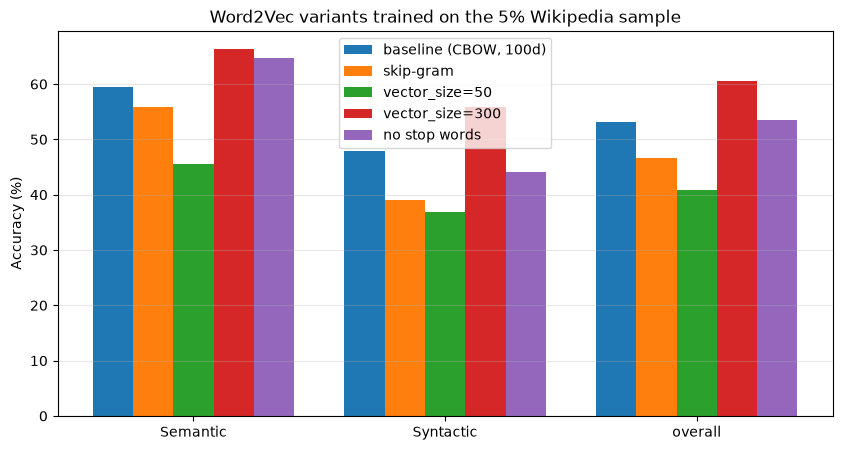

In [12]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Semantic / Syntactic / overall accuracy for each 5% variant
plot_rows = ["Semantic", "Syntactic", "overall"]
x = np.arange(len(plot_rows))
bar_width = 0.8 / len(q5_table.columns)

plt.figure(figsize=(10, 5))
for k, variant in enumerate(q5_table.columns):
    plt.bar(x + k * bar_width, q5_table.loc[plot_rows, variant], bar_width, label=variant)
plt.xticks(x + bar_width * (len(q5_table.columns) - 1) / 2, plot_rows)
plt.ylabel("Accuracy (%)")
plt.title("Word2Vec variants trained on the 5% Wikipedia sample")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("q5_variants.png", bbox_inches="tight")
plt.show()

## requirements.txt

In [2]:
# Generative AI usage: code generated by Claude (Anthropic) under my direction (I set the requirements and chose among its proposed approaches); I reviewed and ran it.
# Export the exact package versions of this runtime (required for submission)
# sys.executable makes sure the pip of this kernel's environment is used
import sys
# PIP_USER=0 overrides a global pip config with user=true, which would hide the packages of this environment
!PIP_USER=0 {sys.executable} -m pip list --format=freeze > requirements.txt
!cat requirements.txt

aiohappyeyeballs==2.7.1
aiohttp==3.14.5
aiosignal==1.4.0
anyio==4.15.1
appnope==1.0.0
asttokens==3.0.2
attrs==26.1.0
click==8.5.0
cloudpickle==3.1.2
comm==0.2.3
contourpy==1.4.0
cycler==0.12.1
datasets==5.1.0
debugpy==1.8.22
dill==0.4.1
executing==2.3.0
fastjsonschema==2.22.2
filelock==4.2.0
fonttools==4.67.0
frozenlist==1.8.0
fsspec==2026.7.0
gensim==4.4.0
h11==0.16.0
hf-xet==1.7.0
httpcore2==2.13.1
httpx2==2.13.1
huggingface_hub==2.2.0
idna==3.20
ipykernel==7.4.0
ipython==9.17.1
ipython_pygments_lexers==1.1.1
ipywidgets==8.1.9
jedi==0.20.1
joblib==1.6.0
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter_client==8.10.0
jupyter_core==5.9.1
jupyterlab_widgets==3.0.17
kiwisolver==1.5.1
matplotlib==3.11.2
matplotlib-inline==0.2.2
multidict==7.1.0
multiprocess==0.70.19
narwhals==2.27.1
nbclient==0.11.0
nbformat==5.11.1
nest-asyncio2==1.7.4
numpy==2.5.4
packaging==26.3
pandas==3.0.6
parso==0.8.7
pexpect==4.9.0
pillow==12.3.0
pip==26.2.1
platformdirs==4.13.0
prompt_toolkit==3.0.5